# 03_Corte de avance | Clasificación de defectos en palta Hass

Proyecto de investigación — ResNet50, clases PICADURA y RUSSET  
Fecha del corte: 25 de octubre de 2026  
Etapa alcanzada: experimentos B0, V1, D1 y D2 evaluados en validación.

Este notebook es un informe breve de lectura. Contiene las conclusiones y gráficas comparativas integradas; no necesita ejecutar entrenamiento ni modificar los archivos del proyecto.

## 1. ¿Qué significan B0, V1, D1 y D2?

Son identificadores de cuatro condiciones experimentales. En todas se emplea la arquitectura ResNet50 preentrenada con ImageNet, con el extractor de características congelado y una cabeza de clasificación para PICADURA y RUSSET.

| Código | Nombre práctico | Resolución (alto × ancho) | Diferencia principal |
|:---|:---|:---|:---|
| B0 | Baseline o referencia | 256 × 512 | Sin aumento de datos. Punto de comparación. |
| V1 | Variante de resolución | 384 × 768 | Entrada de mayor resolución para conservar detalle visual. |
| D1 | Variante de datos 1 | 256 × 512 | Una copia aumentada por cada RUSSET elegible de entrenamiento (77 copias). |
| D2 | Variante de datos 2 | 256 × 512 | Dos copias aumentadas por cada RUSSET elegible de entrenamiento (154 copias). |

En D1 y D2, los aumentos son fotométricos leves (brillo y contraste); no son frutos nuevos y no se voltean las imágenes. El cambio afecta únicamente a train, nunca a validation ni test.

También se consideró V2, con volteo horizontal, pero se descartó porque altera el orden de las vistas capturadas. V2 no tiene resultados experimentales.

## 2. Preparación técnica realizada

Se habilitó un entorno de Python 3.12 y TensorFlow 2.21.0 en Ubuntu WSL2, utilizado desde Visual Studio Code mediante el kernel `palta_gpu (CUDA)`. Se verificó la detección y uso de la NVIDIA GeForce RTX 3070 Ti Laptop GPU mediante CUDA/cuDNN. Se incorporaron las librerías de datos, procesamiento de TIFF y métricas.

Los intentos iniciales de D1 se interrumpieron debido a una comprobación muy estricta de equivalencia numérica entre dos rutas de predicción. La verificación se mantuvo y se ajustaron las tolerancias a `rtol=1e-3` y `atol=1e-4`; la corrida `D1_s42_03` concluyó. Posteriormente concluyó `D2_s42_01`.

Las primeras ejecuciones de referencia B0 y V1 fueron anteriores y se conservaron como comparación. No se reentrenaron durante esta fase.

## 3. Dataset y auditoría

Cada TIFF corresponde a una palta y contiene tres franjas horizontales provenientes de cámaras distintas, con varias vistas de rotación. Se utiliza el archivo completo como muestra; sus vistas no se distribuyen por separado entre conjuntos.

| Conjunto | PICADURA original | RUSSET original | Total original | Archivos elegibles |
|:---|---:|---:|---:|---:|
| train | 497 | 77 | 574 | 572 |
| validation | 107 | 21 | 128 | 127 |
| test (reservado) | 106 | 21 | 127 | 126 |
| Total | 710 | 119 | 829 | 825 |

Se comprobaron los hashes SHA-256 de los 829 archivos. La auditoría propuso excluir lógicamente cuatro rutas relacionadas con dos pares duplicados entre particiones; uno contenía etiquetas contradictorias. Después de la exclusión quedaron 572 imágenes de train, 127 de validation y 126 de test.

No se borraron, movieron ni modificaron los TIFF. Detectar duplicados exactos no prueba por sí solo independencia completa entre fruto, lote o sesión; para eso se requiere trazabilidad adicional.

## 4. Diseño de entrenamiento

- Modelo: ResNet50 con pesos ImageNet, extractor congelado y cabeza de clasificación binaria.
- Semilla de referencia: 42; máximo de 35 épocas, con parada anticipada según la pérdida de validación.
- Desbalance: pesos de clase calculados con el conjunto efectivo de entrenamiento.
- B0 y V1: 572 imágenes elegibles de entrenamiento, sin copias fotométricas adicionales.
- D1: 572 originales + 77 copias RUSSET = 649 muestras efectivas.
- D2: 572 originales + 154 copias RUSSET = 726 muestras efectivas.
- Validación: los mismos 127 archivos elegibles; sin augmentación.
- Test: reservado para la evaluación final, no utilizado para escoger condición.

Las copias fotométricas se generan en memoria y no crean nuevos archivos TIFF.

## 5. Resultados comparativos en validation

Las cifras se obtuvieron de los resultados previos de B0 y V1 y de las salidas de validación de D1 y D2.

| Métrica | B0 | V1 | D1 | D2 |
|:---|---:|---:|---:|---:|
| Accuracy | 0.8425 | 0.8583 | 0.8425 | 0.8583 |
| Macro-F1 | 0.6604 | 0.6598 | **0.7033** | 0.6944 |
| Balanced accuracy | 0.6384 | 0.6287 | **0.6956** | 0.6669 |
| Recall de RUSSET | 0.3333 | 0.2857 | **0.4762** | 0.3810 |
| F1 de RUSSET | 0.4118 | 0.4000 | **0.5000** | 0.4706 |
| RUSSET acertadas / 21 | 7 | 6 | **10** | 8 |

El accuracy mide el porcentaje global de aciertos. El macro-F1 promedia el F1 de cada clase por igual y permite evaluar mejor el comportamiento cuando las clases están desbalanceadas. El recall de RUSSET indica qué fracción de las 21 imágenes RUSSET de validación fue reconocida correctamente.

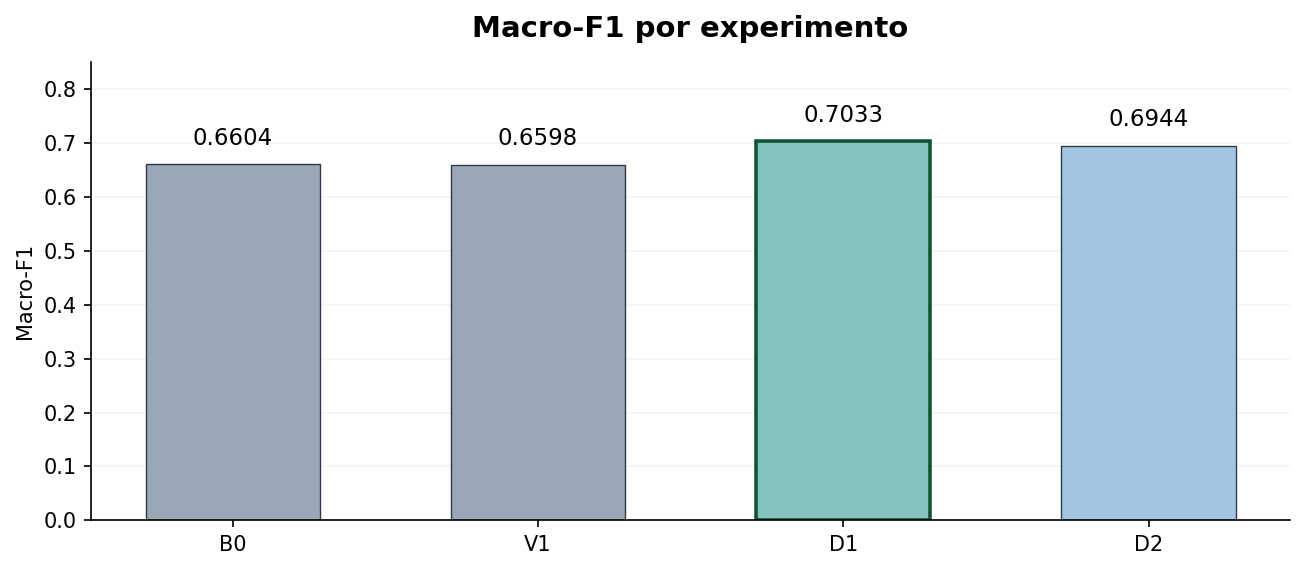

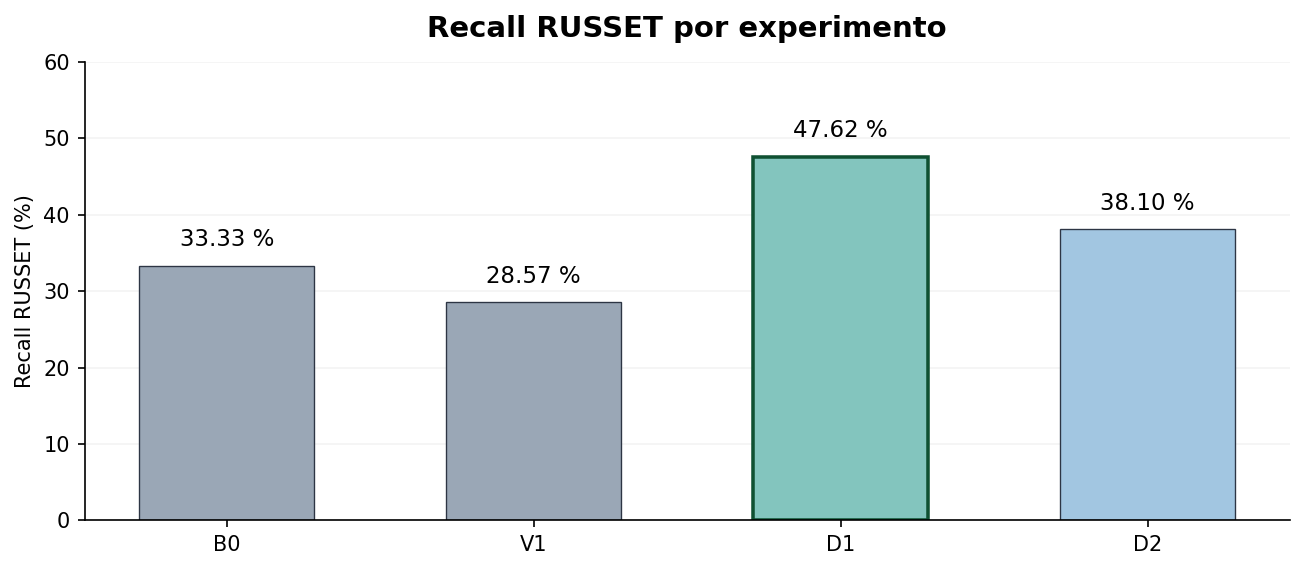

## 6. Matrices de confusión: D1 frente a D2

Filas = etiqueta real. Columnas = etiqueta predicha.

| D1 — Real / Predicción | PICADURA | RUSSET |
|:---|---:|---:|
| PICADURA | 97 | 9 |
| RUSSET | 11 | 10 |

| D2 — Real / Predicción | PICADURA | RUSSET |
|:---|---:|---:|
| PICADURA | 101 | 5 |
| RUSSET | 13 | 8 |

D1 clasificó correctamente 107 de 127 imágenes. D2 clasificó correctamente 109 de 127. Al pasar de D1 a D2 se recuperaron cuatro aciertos de PICADURA, pero se perdieron dos de RUSSET.

Por ello D2 aumenta el accuracy respecto a D1 (84.25 % → 85.83 %), mientras que D1 mantiene un mejor macro-F1 (0.7033 frente a 0.6944) y mejor recall de RUSSET (47.62 % frente a 38.10 %).

## 7. Lectura de las curvas de aprendizaje

En D1 se observó una reducción de la pérdida de entrenamiento y una pérdida de validación con oscilaciones, seguida de estabilización cerca de 0.31. La ejecución mostró alrededor de 19 épocas.

En D2 la pérdida de entrenamiento también disminuyó, mientras que validación osciló y terminó cerca de 0.30; la ejecución mostró 15 épocas. Las curvas son compatibles con la detención anticipada antes del límite de 35 épocas.

La brecha de accuracy entre train y validation en D2 merece seguimiento, pero no permite afirmar por sí sola sobreajuste: las pérdidas de train y validation no se calculan bajo condiciones idénticas, debido a los pesos por clase y al Dropout en entrenamiento.

## 8. Conclusiones del corte

1. El entorno GPU quedó operativo, y D1 y D2 finalizaron con sus métricas y gráficas almacenadas.
2. La auditoría de integridad validó 829 archivos y dejó 825 elegibles sin alterar originales.
3. En esta validación, D1 es la mejor condición provisional por macro-F1 (0.7033), balanced accuracy (0.6956) y recall de RUSSET (10/21).
4. D2 alcanzó mayor accuracy global (0.8583), pero detectó dos RUSSET menos que D1.
5. Generar más copias aumentadas de la clase minoritaria no produjo una mejora monotónica del rendimiento. Los resultados son exploratorios, no una demostración estadística definitiva.

Limitaciones: solo hay 21 imágenes RUSSET en validation; se utilizó una partición fija y una semilla por condición; la trazabilidad por fruto, lote y sesión requiere una revisión adicional. El conjunto test permanece reservado.

## 9. Próxima etapa

1. Conservar B0, V1, D1 y D2 sin sobrescribir sus resultados.
2. Preparar un ensayo controlado de fine-tuning parcial de ResNet50, comparando condiciones con el mismo protocolo y sin utilizar test para tomar decisiones.
3. Repetir al menos las condiciones más prometedoras con distintas semillas si los recursos lo permiten.
4. Revisar los errores RUSSET ↔ PICADURA y estudiar si la confusión se relaciona con textura, apariencia o condiciones de captura.
5. Seleccionar el protocolo final antes de evaluar el conjunto test.

### Ubicaciones de las ejecuciones

- D1: `7. resultados/entrenamiento/D1_s42_03/`
- D2: `7. resultados/entrenamiento/D2_s42_01/`
- Notebook de entrenamiento: `6. entrenamiento/resnet50.ipynb`

Al guardar el notebook de entrenamiento, conservar `ENTRENAR = False` y `EJECUTAR_FT = False`. Este corte es un documento independiente de solo lectura.

---

Fuente de la información: auditoría y configuración del notebook del proyecto, resultados históricos B0/V1 y salidas de validación de D1/D2 compartidas hasta este corte. No se ejecutó entrenamiento para elaborar este informe.